In [8]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/reubensuju/celeb-df-v2/List_of_testing_videos.txt
/kaggle/input/datasets/reubensuju/celeb-df-v2/YouTube-real/00238.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/YouTube-real/00152.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/YouTube-real/00269.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/YouTube-real/00209.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/YouTube-real/00297.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/YouTube-real/00096.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/YouTube-real/00255.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/YouTube-real/00230.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/YouTube-real/00259.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/YouTube-real/00012.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/YouTube-real/00219.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/YouTube-real/00003.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/YouTube-real/00147.mp4
/kaggle/input/datasets/reubens

In [9]:
BASE_PATH = "/kaggle/input/datasets/reubensuju/celeb-df-v2"

In [10]:
import os
import cv2
import numpy as np
import pandas as pd
from tqdm import tqdm

BASE_PATH = "/kaggle/input/datasets/reubensuju/celeb-df-v2"

REAL_CELEB = os.path.join(BASE_PATH, "Celeb-real")
REAL_YOUTUBE = os.path.join(BASE_PATH, "YouTube-real")
FAKE = os.path.join(BASE_PATH, "Celeb-synthesis")

print("Dataset path:", BASE_PATH)
print("Celeb-real:", os.path.exists(REAL_CELEB))
print("YouTube-real:", os.path.exists(REAL_YOUTUBE))
print("Celeb-synthesis:", os.path.exists(FAKE))

Dataset path: /kaggle/input/datasets/reubensuju/celeb-df-v2
Celeb-real: True
YouTube-real: True
Celeb-synthesis: True


In [11]:
sample_video = os.path.join(REAL_CELEB, "id49_0006.mp4")

print("Testing video:", sample_video)
print("Exists:", os.path.exists(sample_video))

Testing video: /kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id49_0006.mp4
Exists: True


In [12]:
def motion_aware_top5(video_path, top_k=5):
    cap = cv2.VideoCapture(video_path)

    frames = []
    motion_scores = []

    ret, prev_frame = cap.read()

    if not ret:
        cap.release()
        return [], []

    prev_gray = cv2.cvtColor(prev_frame, cv2.COLOR_BGR2GRAY)

    frame_index = 0

    while True:
        ret, frame = cap.read()

        if not ret:
            break

        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        # Frame difference
        diff = cv2.absdiff(gray, prev_gray)

        # Motion score
        motion_score = np.mean(diff)

        frames.append((frame_index + 1, frame.copy()))
        motion_scores.append((frame_index + 1, motion_score))

        prev_gray = gray
        frame_index += 1

    cap.release()

    # Select frames with highest motion scores
    motion_scores.sort(key=lambda x: x[1], reverse=True)

    selected = motion_scores[:min(top_k, len(motion_scores))]

    # Sort selected frames according to temporal order
    selected.sort(key=lambda x: x[0])

    selected_frames = []

    frame_dict = {idx: frame for idx, frame in frames}

    for idx, score in selected:
        selected_frames.append((idx, score, frame_dict[idx]))

    return selected_frames, motion_scores

In [13]:
selected_frames, all_motion_scores = motion_aware_top5(
    sample_video,
    top_k=5
)

print("Number of selected frames:", len(selected_frames))

for idx, score, frame in selected_frames:
    print(f"Frame: {idx:4d} | Motion Score: {score:.4f}")

Number of selected frames: 5
Frame:    6 | Motion Score: 7.4730
Frame:   10 | Motion Score: 7.5839
Frame:   67 | Motion Score: 7.0919
Frame:   86 | Motion Score: 7.8938
Frame:  159 | Motion Score: 8.4800


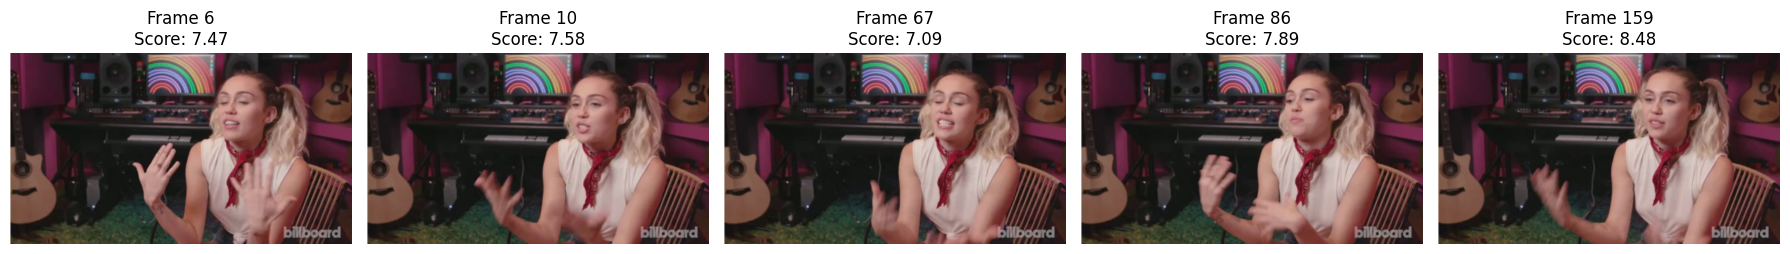

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 4))

for i, (idx, score, frame) in enumerate(selected_frames):
    plt.subplot(1, 5, i + 1)

    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.imshow(frame_rgb)
    plt.title(f"Frame {idx}\nScore: {score:.2f}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [15]:
OUTPUT_ROOT = "/kaggle/working/celebdf_sampled_frames"

REAL_OUTPUT = os.path.join(OUTPUT_ROOT, "Real")
FAKE_OUTPUT = os.path.join(OUTPUT_ROOT, "Fake")

os.makedirs(REAL_OUTPUT, exist_ok=True)
os.makedirs(FAKE_OUTPUT, exist_ok=True)

print("Output root:", OUTPUT_ROOT)
print("Real folder:", REAL_OUTPUT)
print("Fake folder:", FAKE_OUTPUT)

Output root: /kaggle/working/celebdf_sampled_frames
Real folder: /kaggle/working/celebdf_sampled_frames/Real
Fake folder: /kaggle/working/celebdf_sampled_frames/Fake


In [16]:
sample_name = os.path.splitext(os.path.basename(sample_video))[0]

sample_output_dir = os.path.join(REAL_OUTPUT, sample_name)
os.makedirs(sample_output_dir, exist_ok=True)

for i, (idx, score, frame) in enumerate(selected_frames, start=1):

    output_file = os.path.join(
        sample_output_dir,
        f"frame_{i:02d}.jpg"
    )

    cv2.imwrite(output_file, frame)

print("Saved files:")
print(os.listdir(sample_output_dir))

Saved files:
['frame_04.jpg', 'frame_05.jpg', 'frame_03.jpg', 'frame_01.jpg', 'frame_02.jpg']


In [17]:
OUTPUT_ROOT = "/kaggle/working/celebdf_sampled_frames"

os.makedirs(OUTPUT_ROOT, exist_ok=True)

print("Output directory ready:")
print(OUTPUT_ROOT)

Output directory ready:
/kaggle/working/celebdf_sampled_frames


In [18]:
def get_video_files(folder):
    return [
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.lower().endswith(".mp4")
    ]

real_celeb_videos = get_video_files(REAL_CELEB)
real_youtube_videos = get_video_files(REAL_YOUTUBE)
fake_videos = get_video_files(FAKE)

print("Celeb-real:", len(real_celeb_videos))
print("YouTube-real:", len(real_youtube_videos))
print("Celeb-synthesis:", len(fake_videos))
print("Total:", len(real_celeb_videos) + len(real_youtube_videos) + len(fake_videos))

Celeb-real: 590
YouTube-real: 300
Celeb-synthesis: 5639
Total: 6529


In [19]:
test_videos = (
    real_celeb_videos[:5]
    + real_youtube_videos[:3]
    + fake_videos[:2]
)

print("Test videos:", len(test_videos))

Test videos: 10


In [20]:
test_results = []

for video_path in tqdm(test_videos, desc="Testing Top-5 sampling"):

    selected_frames, motion_scores = motion_aware_top5(
        video_path,
        top_k=5
    )

    video_name = os.path.basename(video_path)

    if video_path in real_celeb_videos or video_path in real_youtube_videos:
        label = "Real"
    else:
        label = "Fake"

    test_results.append({
        "video": video_name,
        "label": label,
        "selected_frames": [x[0] for x in selected_frames],
        "motion_scores": [round(x[1], 4) for x in selected_frames]
    })

test_df = pd.DataFrame(test_results)

print("Processing completed.")
print("Videos processed:", len(test_df))

test_df.head(10)

Testing Top-5 sampling: 100%|██████████| 10/10 [00:08<00:00,  1.20it/s]

Processing completed.
Videos processed: 10


,video,label,selected_frames,motion_scores
0,id49_0006.mp4,Real,"[6, 10, 67, 86, 159]","[7.473, 7.5839, 7.0919, 7.8938, 8.48]"
1,id27_0008.mp4,Real,"[52, 56, 58, 67, 73]","[7.4833, 8.6961, 9.2781, 7.2061, 5.9203]"
2,id32_0000.mp4,Real,"[6, 60, 66, 84, 102]","[6.6035, 4.6715, 4.7227, 4.2653, 5.2249]"
3,id1_0006.mp4,Real,"[396, 411, 429, 435, 447]","[3.2932, 2.8075, 3.5321, 3.1464, 3.3986]"
4,id50_0006.mp4,Real,"[66, 67, 70, 73, 76]","[4.2269, 3.6442, 5.1358, 4.0242, 4.0703]"
5,00238.mp4,Real,"[12, 14, 201, 348, 351]","[1.6006, 1.7452, 1.6333, 1.6419, 1.729]"
6,00152.mp4,Real,"[104, 312, 364, 366, 367]","[6.3158, 4.182, 4.7075, 4.8884, 4.1933]"
7,00269.mp4,Real,"[26, 74, 75, 171, 173]","[2.5533, 2.3998, 3.4773, 43.4205, 2.4022]"
8,id33_id20_0005.mp4,Fake,"[197, 203, 204, 248, 345]","[5.6015, 6.3745, 8.8308, 6.4946, 6.2041]"
9,id24_id19_0004.mp4,Fake,"[192, 299, 303, 304, 310]","[8.0633, 6.4364, 6.4181, 5.5641, 7.7129]"


In [21]:
full_videos = (
    real_celeb_videos
    + real_youtube_videos
    + fake_videos
)

print("Total videos to process:", len(full_videos))

Total videos to process: 6529



for video_path in tqdm(full_videos, desc="Processing all Celeb-DF(v2) videos"):

    selected_frames, motion_scores = motion_aware_top5(
        video_path,
        top_k=5
    )

    video_name = os.path.basename(video_path)

    if video_path in real_celeb_videos or video_path in real_youtube_videos:
        label = "Real"
    else:
        label = "Fake"

    full_results.append({
        "video": video_name,
        "label": label,
        "selected_frames": [x[0] for x in selected_frames],
        "motion_scores": [round(x[1], 4) for x in selected_frames]
    })

print("Processing completed.")
print("Total videos processed:", len(full_results))

In [22]:
import os
import pandas as pd
from tqdm import tqdm

BASE_PATH = "/kaggle/input/datasets/reubensuju/celeb-df-v2"

REAL_CELEB = os.path.join(BASE_PATH, "Celeb-real")
REAL_YOUTUBE = os.path.join(BASE_PATH, "YouTube-real")
FAKE = os.path.join(BASE_PATH, "Celeb-synthesis")

def get_video_files(folder):
    return [
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.lower().endswith(".mp4")
    ]

real_celeb_videos = get_video_files(REAL_CELEB)
real_youtube_videos = get_video_files(REAL_YOUTUBE)
fake_videos = get_video_files(FAKE)

full_videos = (
    real_celeb_videos
    + real_youtube_videos
    + fake_videos
)

print("Total videos:", len(full_videos))

Total videos: 6529


In [23]:
CHECKPOINT_PATH = "/kaggle/working/celebdf_top5_checkpoint.csv"

print("Checkpoint file:", CHECKPOINT_PATH)
print("Already exists:", os.path.exists(CHECKPOINT_PATH))

Checkpoint file: /kaggle/working/celebdf_top5_checkpoint.csv
Already exists: False


In [24]:
CHECKPOINT_PATH = "/kaggle/working/celebdf_top5_checkpoint.csv"
SAVE_EVERY = 250

# Existing checkpoint unte load cheyyi
if os.path.exists(CHECKPOINT_PATH):
    checkpoint_df = pd.read_csv(CHECKPOINT_PATH)
    processed_videos = set(checkpoint_df["video"].astype(str))
    results = checkpoint_df.to_dict("records")
    print(f"Resuming from {len(processed_videos)} processed videos...")
else:
    processed_videos = set()
    results = []
    print("Starting from the beginning...")

for i, video_path in enumerate(
    tqdm(full_videos, desc="Celeb-DF(v2) Top-5 Sampling"),
    start=1
):

    video_name = os.path.basename(video_path)

    # Already processed video → skip
    if video_name in processed_videos:
        continue

    selected_frames, motion_scores = motion_aware_top5(
        video_path,
        top_k=5
    )

    if video_path in real_celeb_videos or video_path in real_youtube_videos:
        label = "Real"
    else:
        label = "Fake"

    results.append({
        "video": video_name,
        "label": label,
        "selected_frames": [x[0] for x in selected_frames],
        "motion_scores": [round(x[1], 4) for x in selected_frames]
    })

    processed_videos.add(video_name)

    # Checkpoint every 250 newly processed videos
    if len(results) % SAVE_EVERY == 0:
        checkpoint_df = pd.DataFrame(results)
        checkpoint_df.to_csv(CHECKPOINT_PATH, index=False)

        print(
            f"\nCheckpoint saved: "
            f"{len(checkpoint_df)}/{len(full_videos)} videos"
        )

# Final save
checkpoint_df = pd.DataFrame(results)
checkpoint_df.to_csv(CHECKPOINT_PATH, index=False)

print("\nProcessing completed.")
print("Total videos processed:", len(checkpoint_df))
print("Checkpoint:", CHECKPOINT_PATH)

Starting from the beginning...


Celeb-DF(v2) Top-5 Sampling:   4%|▍         | 250/6529 [03:15<1:13:09,  1.43it/s]


Checkpoint saved: 250/6529 videos


Celeb-DF(v2) Top-5 Sampling:   8%|▊         | 500/6529 [06:20<1:12:12,  1.39it/s]


Checkpoint saved: 500/6529 videos


...


Checkpoint saved: 6250/6529 videos


Celeb-DF(v2) Top-5 Sampling: 100%|█████████▉| 6500/6529 [1:21:54<00:21,  1.35it/s]


Checkpoint saved: 6500/6529 videos


Celeb-DF(v2) Top-5 Sampling: 100%|██████████| 6529/6529 [1:22:17<00:00,  1.32it/s]


Processing completed.
Total videos processed: 6529
Checkpoint: /kaggle/working/celebdf_top5_checkpoint.csv


In [26]:
print("Total sampled videos:", len(final_df))

NameError: name 'final_df' is not defined

In [27]:
import os
import pandas as pd

CHECKPOINT_PATH = "/kaggle/working/celebdf_top5_checkpoint.csv"

print("Checkpoint exists:", os.path.exists(CHECKPOINT_PATH))

if os.path.exists(CHECKPOINT_PATH):
    check_df = pd.read_csv(CHECKPOINT_PATH)
    print("Checkpoint rows:", len(check_df))

Checkpoint exists: True
Checkpoint rows: 6529


In [29]:
final_df = check_df.copy()

FINAL_PATH = "/kaggle/working/celebdf_top5_final.csv"

final_df.to_csv(FINAL_PATH, index=False)

print("Total sampled videos:", len(final_df))
print("Final file saved:", FINAL_PATH)

Total sampled videos: 6529
Final file saved: /kaggle/working/celebdf_top5_final.csv


In [30]:
import os
import pandas as pd

FINAL_PATH = "/kaggle/working/celebdf_top5_final.csv"
CHECKPOINT_PATH = "/kaggle/working/celebdf_top5_checkpoint.csv"

print("Final file:", os.path.exists(FINAL_PATH))
print("Checkpoint:", os.path.exists(CHECKPOINT_PATH))

if os.path.exists(FINAL_PATH):
    df = pd.read_csv(FINAL_PATH)
    print("Final rows:", len(df))

elif os.path.exists(CHECKPOINT_PATH):
    df = pd.read_csv(CHECKPOINT_PATH)
    print("Checkpoint rows:", len(df))

Final file: True
Checkpoint: True
Final rows: 6529
